# Planetary health datasets

Four datasets linking the environment to health.
Run **Setup**, browse the four, then choose one with your group
and work through its **Explore** list.


## Setup


In [4]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

REPOSITORY = "QuantitativeBiology/PlanetaryHealth_SystemsScience"
BASE_URL = f"https://raw.githubusercontent.com/{REPOSITORY}/main/data"

mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,
        "axes.titlesize": 9,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "pdf.fonttype": 42,
        "svg.fonttype": "none",
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
    }
)
mpl.rcParams["figure.dpi"] = 150  # sharper figures in the notebook


def load(name, **options):
    """Read a dataset from the local data folder, or from GitHub."""
    local = Path("data") / name
    source = local if local.exists() else f"{BASE_URL}/{name}"
    return pd.read_csv(source, **options)


def mae(observed, predicted):
    """Mean absolute error."""
    return float(np.mean(np.abs(observed - predicted)))


def mape(observed, predicted):
    """Mean absolute percentage error."""
    return float(100 * np.mean(np.abs(observed - predicted) / observed))


def plot_fit(dates, observed, predicted, ylabel, marker=None):
    """Observed and predicted values over time."""
    fig, axis = plt.subplots(figsize=(7.2, 2.4))
    axis.plot(dates, observed, lw=0.6, marker=marker, ms=3, label="Observed")
    axis.plot(dates, predicted, lw=0.9, marker=marker, ms=3, label="Model")
    axis.set(title="Observed and predicted", ylabel=ylabel)
    axis.legend(frameon=False)
    plt.show()


def fit_predict(train, test, features, target):
    """Fit gradient boosting on train; return test rows with predictions."""
    columns = features + [target]
    train, test = train.dropna(subset=columns), test.dropna(subset=columns)
    model = GradientBoostingRegressor(random_state=0)
    model.fit(train[features], train[target])
    return test.assign(predicted=model.predict(test[features]))

## 1. Chicago: daily deaths, weather and air pollution, 1987–2000

One row per day. Outcome: `death`, `cvd`, `resp`.
Exposures: `temp`, `dptp`, `rhum`, `pm10`, `o3`.
Source: NMMAPS study, Chicago subset from the R package `dlnm`.

**Guess first:** was the deadliest day of these 14 years in winter or
in summer?


In [5]:
chicago = load("chicago_daily_1987_2000.csv", parse_dates=["date"])
print(chicago.shape)
chicago.head()

(5114, 14)


,date,time,year,month,doy,dow,death,cvd,resp,temp,dptp,rhum,pm10,o3
0,1987-01-01,1,1987,1,1,Thursday,130,65,13,-0.277778,31.500,95.50,26.956074,4.376079
1,1987-01-02,2,1987,1,2,Friday,150,73,14,0.555556,29.875,88.25,NaN,4.929803
2,1987-01-03,3,1987,1,3,Saturday,101,43,11,0.555556,27.375,89.50,32.838695,3.751079
3,1987-01-04,4,1987,1,4,Sunday,135,72,7,-1.666667,28.625,84.50,39.956074,4.292746
4,1987-01-05,5,1987,1,5,Monday,126,64,12,0.000000,28.875,74.50,NaN,4.751079


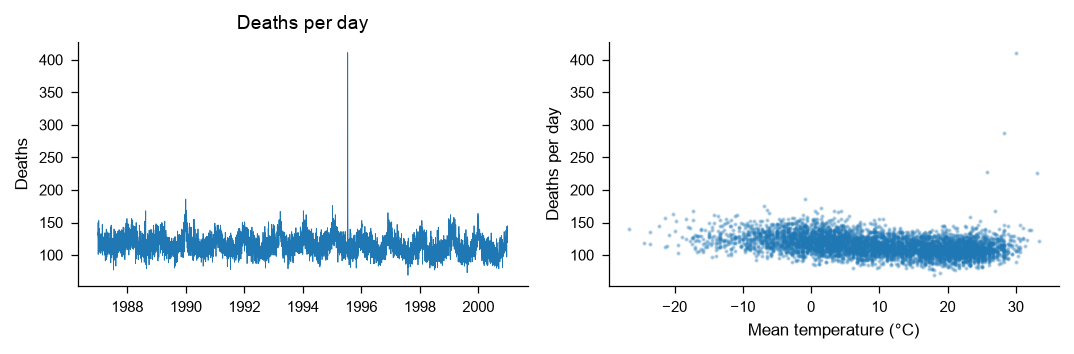

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(7.2, 2.4))
left.plot(chicago.date, chicago.death, lw=0.4)
left.set(title="Deaths per day", ylabel="Deaths")
right.scatter(chicago.temp, chicago.death, s=1, alpha=0.3)
right.set(xlabel="Mean temperature (°C)", ylabel="Deaths per day")
fig.tight_layout()
plt.show()

Yesterday's deaths: 12.5
Day-of-year average: 11.3
Model: 11.0


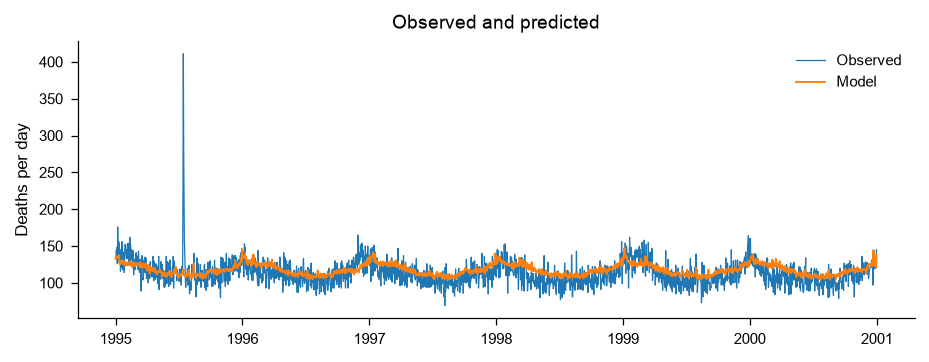

In [7]:
# Train on 1987-1994, test on 1995-2000
chicago["weekday"] = chicago.date.dt.dayofweek
chicago["yesterday"] = chicago.death.shift(1)
train = chicago[chicago.year <= 1994]
test = chicago[chicago.year >= 1995]
features = ["temp", "pm10", "o3", "weekday", "doy", "year"]
result = fit_predict(train, test, features, "death")
seasonal = test.doy.map(train.groupby("doy").death.mean())

print("Yesterday's deaths:", round(mae(test.death, test.yesterday), 1))
print("Day-of-year average:", round(mae(test.death, seasonal), 1))
print("Model:", round(mae(result.death, result.predicted), 1))
plot_fit(result.date, result.death, result.predicted, "Deaths per day")

**Explore**

1. Which columns have gaps or impossible values?
2. How related are `temp` and `dptp`? Does a model need both?
3. Is deaths against temperature a straight line?
4. Find the trend, the season and the day-of-week effect.
5. Does the model beat both baselines? By how much?
6. Find the biggest miss in the plot. What was the weather just before?
7. Does adding `pm10` and `o3` help? Is a small effect unimportant?


## 2. Lisbon weekly mortality and Copernicus climate data, 2000–2025

One row per week. Outcome: `deaths_lisbon_ama`, `deaths_portugal`.
Exposures: weekly temperature, humidity and air quality.
Sources: Eurostat deaths; Copernicus ERA5-Land weather and CAMS air
quality, averaged to weeks for one point in central Lisbon.

**Guess first:** at what weekly temperature are deaths lowest: about
15, 20 or 25 °C?


In [8]:
lisbon = load(
    "lisbon_weekly_mortality_2000_2025.csv", parse_dates=["week_start"]
)
print(lisbon.shape)
lisbon.tail()

(1356, 16)


,week,week_start,year,week_of_year,deaths_lisbon_ama,deaths_portugal,tmean,tmax_mean,tmax_max,tmin_mean,rhum,days_tmax_over_35,pm10,pm25,o3,no2
1351,2025-W48,2025-11-24,2025,48,NaN,2505.0,13.17,15.34,17.0,11.07,78.57,0,13.88,8.45,53.50,17.05
1352,2025-W49,2025-12-01,2025,49,NaN,2688.0,13.96,15.39,16.4,12.53,83.57,0,14.79,7.99,59.17,17.16
1353,2025-W50,2025-12-08,2025,50,NaN,2803.0,13.79,15.43,16.5,12.13,85.43,0,12.88,9.00,49.76,15.20
1354,2025-W51,2025-12-15,2025,51,NaN,2812.0,12.23,13.94,14.9,10.71,81.29,0,14.09,8.49,58.11,14.33
1355,2025-W52,2025-12-22,2025,52,NaN,3049.0,10.83,12.73,13.9,9.03,81.00,0,14.32,10.33,48.58,17.14


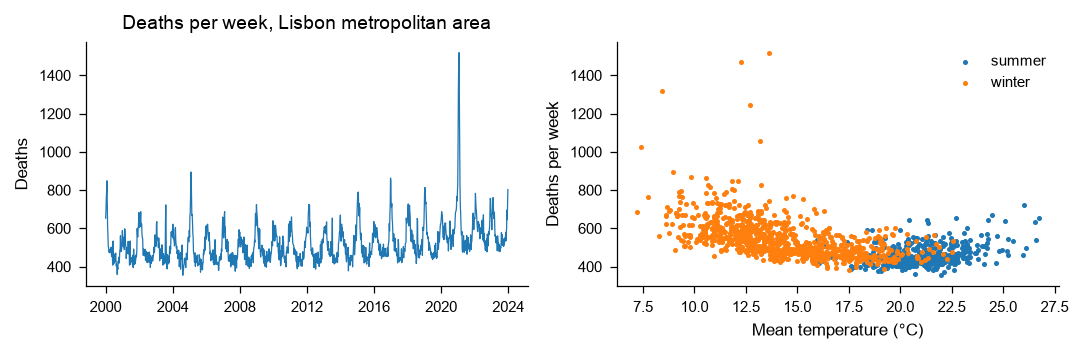

In [9]:
summer = lisbon.week_of_year.between(22, 39)
fig, (left, right) = plt.subplots(1, 2, figsize=(7.2, 2.4))
left.plot(lisbon.week_start, lisbon.deaths_lisbon_ama, lw=0.6)
left.set(title="Deaths per week, Lisbon metropolitan area", ylabel="Deaths")
for label, weeks in [("summer", lisbon[summer]), ("winter", lisbon[~summer])]:
    right.scatter(weeks.tmean, weeks.deaths_lisbon_ama, s=2, label=label)
right.set(xlabel="Mean temperature (°C)", ylabel="Deaths per week")
right.legend(frameon=False)
fig.tight_layout()
plt.show()

Last week's deaths: 40.5
Week-of-year average: 89.2
Model: 69.3


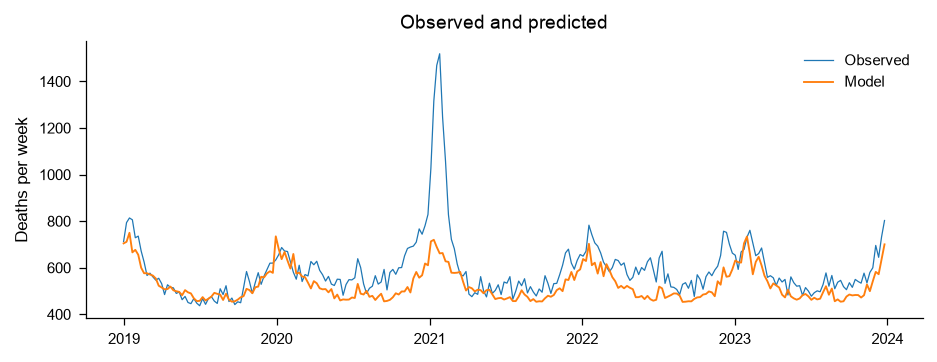

In [10]:
# Train on 2000-2018, predict 2019-2023, score without 2020
weeks = lisbon.dropna(subset=["deaths_lisbon_ama"]).copy()
weeks["last_week"] = weeks.deaths_lisbon_ama.shift(1)
train = weeks[weeks.year <= 2018]
later = weeks[weeks.year >= 2019]
features = ["tmean", "tmax_mean", "tmax_max", "tmin_mean", "rhum"]
features += ["days_tmax_over_35", "week_of_year", "year"]
result = fit_predict(train, later, features, "deaths_lisbon_ama")
test = result[result.year != 2020]
by_week = train.groupby("week_of_year").deaths_lisbon_ama.mean()
seasonal = test.week_of_year.map(by_week)
deaths = test.deaths_lisbon_ama

print("Last week's deaths:", round(mae(deaths, test.last_week), 1))
print("Week-of-year average:", round(mae(deaths, seasonal), 1))
print("Model:", round(mae(deaths, test.predicted), 1))
plot_fit(
    result.week_start,
    result.deaths_lisbon_ama,
    result.predicted,
    "Deaths per week",
)

**Explore**

1. Where do the Lisbon deaths stop? Where does air quality start?
2. What is lost in weekly data? How related are the temperature columns?
3. Correlate deaths and temperature in summer and in winter separately.
4. Deaths rise over the years. Is Lisbon less healthy? What is missing?
5. Which predictor wins on the test years, and why?
6. Find the biggest misses in the plot. Then train on 2000–2002 and
   predict weeks 30–34 of 2003.
7. Weather comes from one point. Who is badly represented by it?


## 3. SNS emergency visits per hospital group, Portugal, 2013–2026

One row per hospital group and month. Outcome: `ed_visits_*`.
Exposures: monthly temperature for the region's reference city.
Sources: SNS Portal da Transparência (year-to-date counts turned into
monthly counts); NASA POWER temperature; INE deaths by cause and region.

**Guess first:** do months with very hot days bring more emergency
visits than usual?


In [11]:
hospitals = load("sns_emergency_visits_monthly_2013_2026.csv")
deaths_by_cause = load("ine_deaths_by_cause_region_2020_2021.csv")
print(hospitals.shape, hospitals.hospital_group.nunique(), "group names")
hospitals.head()

(6561, 19) 79 group names


,month,year,month_of_year,region,hospital_group,lat,lon,ed_visits_total,ed_visits_general,ed_visits_paediatric,ed_visits_obstetric,ed_visits_psychiatric,weather_city,tmean,tmax_mean,tmax_max,tmin_min,days_tmax_over_35,days_tmin_under_5
0,2013-01,2013,1,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE",38.66,-9.06,4192.0,838.0,NaN,3354.0,NaN,Lisboa,13.46,14.94,16.45,8.91,0,0
1,2013-02,2013,2,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE",38.66,-9.06,20571.0,15811.0,6549.0,-1789.0,NaN,Lisboa,12.04,13.90,15.78,6.91,0,0
2,2013-03,2013,3,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE",38.66,-9.06,13043.0,8810.0,3431.0,802.0,NaN,Lisboa,13.46,14.82,16.28,7.91,0,0
3,2013-04,2013,4,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE",38.66,-9.06,12176.0,8326.0,3091.0,759.0,NaN,Lisboa,14.62,16.67,20.62,9.75,0,0
4,2013-05,2013,5,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE",38.66,-9.06,12777.0,8661.0,3241.0,875.0,NaN,Lisboa,15.28,17.48,20.45,11.08,0,0


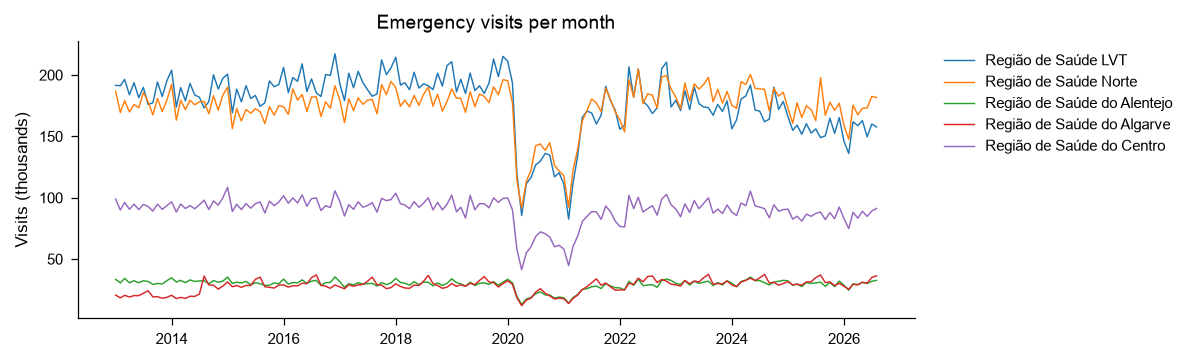

In [13]:
region = hospitals.groupby(["region", "month"], as_index=False).agg(
    visits=("ed_visits_total", "sum"),
    tmean=("tmean", "first"),
    hot_days=("days_tmax_over_35", "first"),
    year=("year", "first"),
    month_of_year=("month_of_year", "first"),
)
region["date"] = pd.to_datetime(region.month)

fig, axis = plt.subplots(figsize=(7.2, 2.4))
for name, months in region.groupby("region"):
    axis.plot(months.date, months.visits / 1e3, lw=0.7, label=name)
axis.set(title="Emergency visits per month", ylabel="Visits (thousands)")
axis.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

Same month last year: 3.2
Model: 4.2


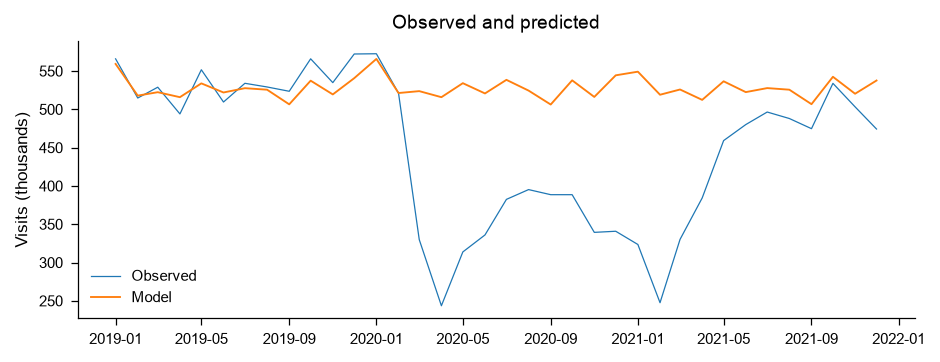

In [14]:
# Train on 2014-2018, predict 2019-2021, score on 2019
region["region_code"] = region.region.astype("category").cat.codes
region["last_year"] = region.groupby("region").visits.shift(12)
train = region[region.year.between(2014, 2018)]
later = region[region.year.between(2019, 2021)]
features = ["tmean", "hot_days", "month_of_year", "region_code", "year"]
result = fit_predict(train, later, features, "visits")
test = result[result.year == 2019]
national = result.groupby("date")[["visits", "predicted"]].sum() / 1e3

print("Same month last year:", round(mape(test.visits, test.last_year), 1))
print("Model:", round(mape(test.visits, test.predicted), 1))
plot_fit(
    national.index, national.visits, national.predicted, "Visits (thousands)"
)

**Explore**

1. How would you check the monthly counts? Any impossible values?
2. Count hospital group names per year and overall. What happened in 2024?
3. Why are psychiatric and paediatric visits missing in many rows?
4. Is the total seasonal? Is the paediatric share?
5. Does weather predict visits? Why might the Algarve differ?
6. Where does the model fail in the plot? Compare 2020 with 2019.
7. Open `deaths_by_cause`. Which comparisons between regions are safe?


## 4. Dar es Salaam: cholera cases and weather, 2015–2018

One row per suspected case. Outcome: `lab_positive`, `outcome`.
Exposures: weather on the day, district, ward, water source.
Source: CholeraClima-TZ, Zenodo 22695115. A second table counts cases
per week and adds Copernicus ERA5 weather for every week.

**Guess first:** of every 100 suspected cases, how many were confirmed
in the laboratory: 7, 40 or 80?


In [15]:
cholera = load("cholera_daressalaam_cases_2015_2018.csv", parse_dates=["date"])
weekly = load("cholera_daressalaam_weekly_2015_2018.csv", parse_dates=["week"])
print(cholera.shape, "positive share:", cholera.lab_positive.mean().round(2))
cholera.head()

(2951, 23) positive share: 0.07


,date,district,ward,age,sex,occupation,diarrhoea,vomiting,severe_dehydration,lab_positive,...,tmax,tmin,tmean,trange,humidity,wind_dir,wind_speed,clean_water_code,wastewater_code,political_code
0,2015-05-09,KINONDONI,KINONDONI,20.0,F,student/dependent,Yes,Yes,Yes,0,...,31.4,22.6,27.00,8.8,81,180,10,1,1,1.0
1,2015-08-06,KINONDONI,KIGOGO,11.0,M,jobless,Yes,Yes,Yes,0,...,30.5,20.4,25.45,10.1,77,170,4,1,2,1.0
2,2015-08-14,KINONDONI,MANZESE,21.0,M,student/dependent,Yes,No,Yes,0,...,33.8,20.3,27.05,13.5,81,180,5,1,2,1.0
3,2015-08-14,KINONDONI,MANZESE,45.0,M,house wife,Yes,No,Yes,1,...,33.8,20.3,27.05,13.5,81,180,5,1,2,1.0
4,2015-08-14,KINONDONI,KIJITONYAMA,15.0,M,student/dependent,Yes,No,Yes,0,...,33.8,20.3,27.05,13.5,81,180,5,1,1,1.0


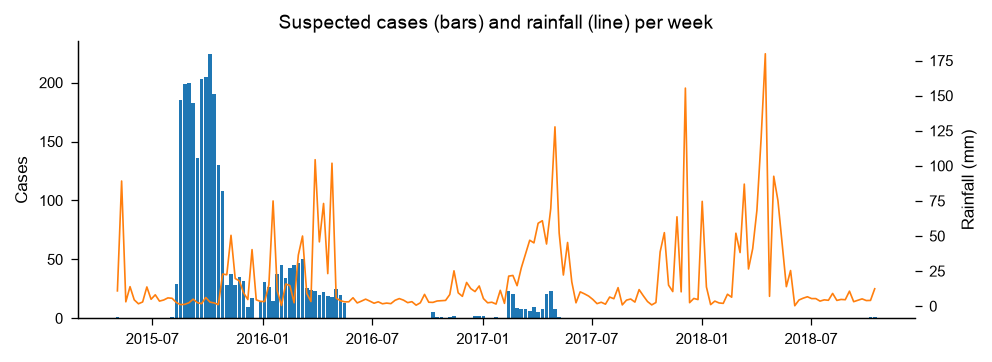

In [16]:
fig, cases_axis = plt.subplots(figsize=(7.2, 2.4))
rain_axis = cases_axis.twinx()
cases_axis.bar(weekly.week, weekly.suspected, width=6)
rain_axis.plot(weekly.week, weekly.era5_rain_mm, color="tab:orange", lw=0.8)
cases_axis.set(title="Suspected cases (bars) and rainfall (line) per week")
cases_axis.set_ylabel("Cases")
rain_axis.set_ylabel("Rainfall (mm)")
plt.show()

Accuracy of always saying negative: 0.93
AUC, random split of records: 0.81
AUC, whole days kept together: 0.57


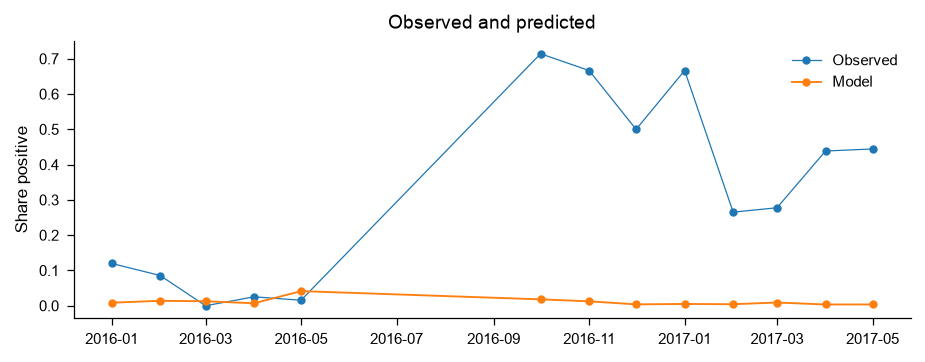

In [17]:
# Can the weather on the day tell a confirmed case from an unconfirmed one?
weather = ["rainfall_mm", "tmax", "tmin", "humidity", "wind_speed"]
inputs, target = cholera[weather], cholera.lab_positive
model = GradientBoostingClassifier(random_state=0)
random_split = StratifiedKFold(5, shuffle=True, random_state=0)
auc_random = cross_val_score(
    model, inputs, target, scoring="roc_auc", cv=random_split
)
auc_by_day = cross_val_score(
    model,
    inputs,
    target,
    scoring="roc_auc",
    cv=GroupKFold(5),
    groups=cholera.date.astype(str),
)

print("Accuracy of always saying negative:", round(1 - target.mean(), 2))
print("AUC, random split of records:", round(auc_random.mean(), 2))
print("AUC, whole days kept together:", round(auc_by_day.mean(), 2))

# Train on 2015, predict 2016-2017: share positive per month
train = cholera[cholera.date < "2016"]
later = cholera[cholera.date.between("2016", "2017-12-31")].copy()
model.fit(train[weather], train.lab_positive)
later["predicted"] = model.predict_proba(later[weather])[:, 1]
month = later.date.dt.to_period("M").dt.start_time
monthly = later.groupby(month)[["lab_positive", "predicted"]].mean()
plot_fit(
    monthly.index,
    monthly.lab_positive,
    monthly.predicted,
    "Share positive",
    marker="o",
)

**Explore**

1. A row is a person with symptoms. Can you compute population risk?
2. Check the symptom values, zeros in the weather, `political_code`.
3. What share is positive? Why is accuracy a misleading score?
4. Compare the positive share by year and by district.
5. Why do the two AUC values differ? What does the model miss in the plot?
6. When did the outbreak peak, and how wet was that period?
7. The case file has weather only on case days. Why is that a problem?

Bonus: `bengal_cholera_monthly_1891_1941.csv`, 50 years of monthly cholera
deaths in 27 districts of British Bengal.


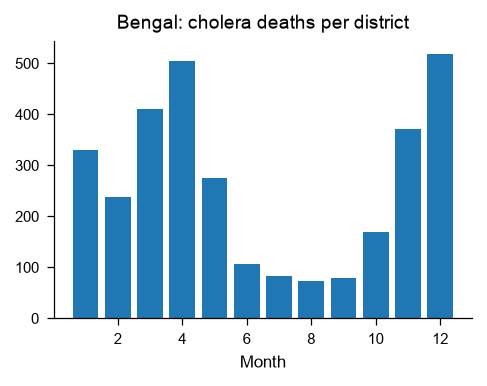

In [18]:
bengal = load("bengal_cholera_monthly_1891_1941.csv")
by_month = bengal.groupby("month").cholera_deaths.mean()

fig, axis = plt.subplots(figsize=(3.6, 2.4))
axis.bar(by_month.index, by_month.values)
axis.set(title="Bengal: cholera deaths per district", xlabel="Month")
plt.show()